# EDA benchmark OpenOOD v1.5

Dữ liệu CURE dùng ở giai đoạn benchmark:
- **ID:** CIFAR-10, CIFAR-100, ImageNet-200
- **OOD:** các tập near-OOD và far-OOD chính thức của OpenOOD v1.5
- **Trôi dạt:** CIFAR-10-C

Phần A xem ảnh gốc (mục 1-6), phần B xem đặc trưng ResNet18 mà thử nghiệm dùng (mục 7-10), mục 11 tóm tắt.

## Cấu hình dữ liệu

**Ghép ID và OOD.** Theo OpenOOD v1.5, dùng nguyên checkpoint và danh sách ảnh chính thức.

| Bộ ID | Near-OOD | Far-OOD | Backbone |
|---|---|---|---|
| CIFAR-10 | CIFAR-100, TinyImageNet | MNIST, SVHN, Textures, Places365 | ResNet18, SupCon, DINOv2 |
| CIFAR-100 | CIFAR-10, TinyImageNet | MNIST, SVHN, Textures, Places365 | ResNet18 |
| ImageNet-200 | SSB-hard, NINCO | Textures | ResNet18 |

**Near và far.** Cách chia lấy nguyên từ OpenOOD v1.5, không tự đặt.
- Near-OOD: chỉ khác lớp, còn kiểu ảnh giống ID (ảnh vật thể tự nhiên, cùng độ phân giải). Ảnh thuộc lớp trùng với ID đã được OpenOOD lọc bỏ.
- Far-OOD: khác cả lớp lẫn kiểu ảnh (chữ số, số nhà, vân bề mặt, cảnh).

**Dựng luồng thử nghiệm.** Do script thử nghiệm làm, notebook này không dựng luồng.
- Gallery là ID train, tập hiệu chuẩn là ID val. ImageNet-200 không có train nên chia đôi ID test (mục 1).
- Mỗi luồng gồm một bộ ID, một tập OOD, tỉ lệ OOD π ∈ {5, 20, 50}% và một seed.
- Lấy toàn bộ ID test, rút ngẫu nhiên ảnh OOD sao cho OOD chiếm π; tập OOD không đủ thì bớt ID. Sau đó xáo trộn và chia thành batch 128 ảnh.
- Tổng cộng 27 cặp (ID, OOD) × 3 mức π = 81 nhóm, mỗi nhóm chạy 3 seed (0-2); seed 3-5 dùng để xác nhận.

**Vị trí dữ liệu.** Tất cả có trên Hugging Face `3chh/cure-data`. Ảnh (`images/`, cho phần A) giải nén vào `IMG_ROOTS`; đặc trưng (`features/`, cho phần B) chép vào `FEAT`.

In [1]:
from pathlib import Path
from collections import Counter
import hashlib, numpy as np, pandas as pd, matplotlib.pyplot as plt
from PIL import Image
from sklearn.metrics import roc_auc_score
from sklearn.manifold import TSNE

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
LISTS = ROOT / 'baselines_official/OODD/data/benchmark_imglist'
IMG_ROOTS = [ROOT / 'baselines_official/OODD/data/images_classic', Path('D:/cure_data/in200')]  # CIFAR/OOD cổ điển; ImageNet-200
FEAT = ROOT / 'data/openood_features'
C = ['#2a78d6', '#eb6834', '#1baf7a', '#4a3aa7', '#e34948', '#eda100', '#e87ba4', '#008300']
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
RNG = np.random.default_rng(0)

def read_list(name):
    rows = [l.split() for l in (LISTS / name).read_text().splitlines() if l.strip()]
    return pd.DataFrame({'path': [r[0] for r in rows], 'label': [int(r[1]) for r in rows]})

def resolve(p):
    for r in IMG_ROOTS:
        if (r / p).exists():
            return r / p
    return None

# Phần A. Ảnh gốc

## 1. Danh mục

Mỗi bộ ID có train (gallery của kNN), val (tập hiệu chuẩn) và test (dữ liệu quen trong luồng). Tập OOD chỉ dùng trong luồng.

In [2]:
SETS = {
 'CIFAR-10':     {'train': 'cifar10/train_cifar10.txt', 'val': 'cifar10/val_cifar10.txt', 'test': 'cifar10/test_cifar10.txt',
                  'near': {'CIFAR-100': 'cifar10/test_cifar100.txt', 'TinyImageNet': 'cifar10/test_tin.txt'},
                  'far': {'MNIST': 'cifar10/test_mnist.txt', 'SVHN': 'cifar10/test_svhn.txt',
                          'Textures': 'cifar10/test_texture.txt', 'Places365': 'cifar10/test_places365.txt'}},
 'CIFAR-100':    {'train': 'cifar100/train_cifar100.txt', 'val': 'cifar100/val_cifar100.txt', 'test': 'cifar100/test_cifar100.txt',
                  'near': {'CIFAR-10': 'cifar100/test_cifar10.txt', 'TinyImageNet': 'cifar100/test_tin.txt'},
                  'far': {'MNIST': 'cifar100/test_mnist.txt', 'SVHN': 'cifar100/test_svhn.txt',
                          'Textures': 'cifar100/test_texture.txt', 'Places365': 'cifar100/test_places365.txt'}},
 'ImageNet-200': {'test': 'imagenet200/test_imagenet200.txt',
                  'near': {'SSB-hard': 'imagenet200/test_ssb_hard.txt', 'NINCO': 'imagenet200/test_ninco.txt'},
                  'far': {'Textures': 'imagenet200/test_textures.txt'}},
}
L, rows = {}, []
for ds, s in SETS.items():
    for role in ('train', 'val', 'test'):
        if role in s:
            df = read_list(s[role]); L[(ds, role)] = df
            rows.append([ds, f'ID {role}', len(df), df.label.nunique()])
    for kind in ('near', 'far'):
        for name, f in s[kind].items():
            df = read_list(f); L[(ds, name)] = df
            rows.append([ds, f'{kind}-OOD: {name}', len(df), '-'])
catalog = pd.DataFrame(rows, columns=['Bộ ID', 'Tập', 'Số ảnh', 'Số lớp'])
catalog

,Bộ ID,Tập,Số ảnh,Số lớp
0,CIFAR-10,ID train,50000,10
1,CIFAR-10,ID val,1000,10
2,CIFAR-10,ID test,9000,10
3,CIFAR-10,near-OOD: CIFAR-100,9000,-
4,CIFAR-10,near-OOD: TinyImageNet,7793,-
5,CIFAR-10,far-OOD: MNIST,70000,-
6,CIFAR-10,far-OOD: SVHN,26032,-
7,CIFAR-10,far-OOD: Textures,5640,-
8,CIFAR-10,far-OOD: Places365,35195,-
9,CIFAR-100,ID train,50000,100


**Ghi chú**
- ImageNet-200 không có train trên máy nên chỉ dùng test, chia đôi theo lớp: nửa A làm gallery (80%) và tập hiệu chuẩn (20%), nửa B làm dữ liệu quen của luồng.
- Tập OOD lớn (MNIST, Places365, SSB-hard) được lấy mẫu khi dựng luồng để giữ đúng tỉ lệ π.

## 2. Phân bố lớp

Lớp lệch thì điểm kNN thiên về lớp đông.

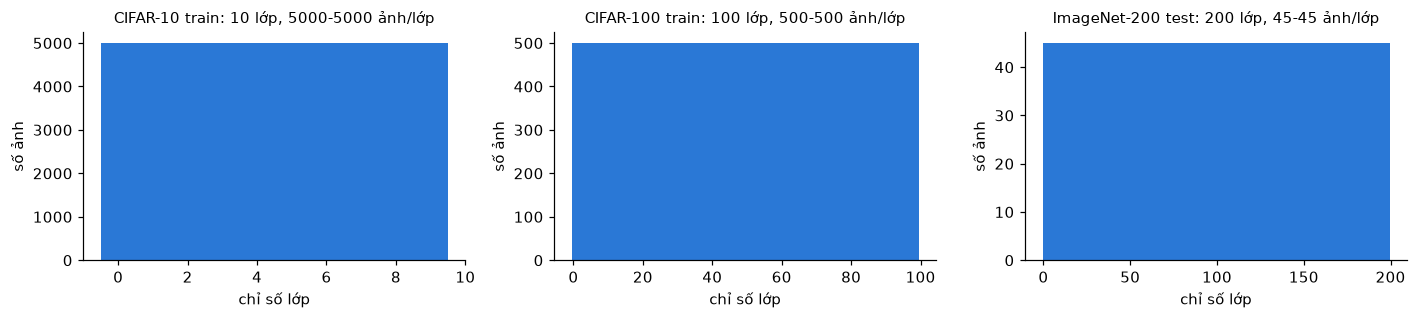

,CIFAR-10 train,CIFAR-10 val,CIFAR-10 test,CIFAR-100 train,CIFAR-100 val,CIFAR-100 test,ImageNet-200 test
count,10.0,10.0,10.0,100.0,100.0,100.0,200.0
min,5000.0,100.0,900.0,500.0,10.0,90.0,45.0
mean,5000.0,100.0,900.0,500.0,10.0,90.0,45.0
max,5000.0,100.0,900.0,500.0,10.0,90.0,45.0


In [3]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3))
for ax, (ds, role) in zip(axes, [('CIFAR-10', 'train'), ('CIFAR-100', 'train'), ('ImageNet-200', 'test')]):
    cnt = L[(ds, role)].label.value_counts().sort_index()
    ax.bar(cnt.index, cnt.values, color=C[0], width=1.0)
    ax.set_title(f'{ds} {role}: {len(cnt)} lớp, {cnt.min()}-{cnt.max()} ảnh/lớp', fontsize=10)
    ax.set_xlabel('chỉ số lớp'); ax.set_ylabel('số ảnh')
plt.tight_layout(); plt.show()
pd.DataFrame({f'{ds} {r}': L[(ds, r)].label.value_counts().describe()[['count', 'min', 'mean', 'max']]
              for ds, r in [('CIFAR-10', 'train'), ('CIFAR-10', 'val'), ('CIFAR-10', 'test'), ('CIFAR-100', 'train'),
                            ('CIFAR-100', 'val'), ('CIFAR-100', 'test'), ('ImageNet-200', 'test')]}).round(1)

**Nhận xét**
- Cả ba bộ ID cân bằng lớp: CIFAR-10 có 5.000 / 100 / 900 ảnh mỗi lớp (train / val / test), CIFAR-100 có 500 / 10 / 90, ImageNet-200 có 45 ảnh mỗi lớp ở test.
- Tập hiệu chuẩn của CIFAR-100 chỉ có 10 ảnh mỗi lớp.

## 3. Ảnh mẫu

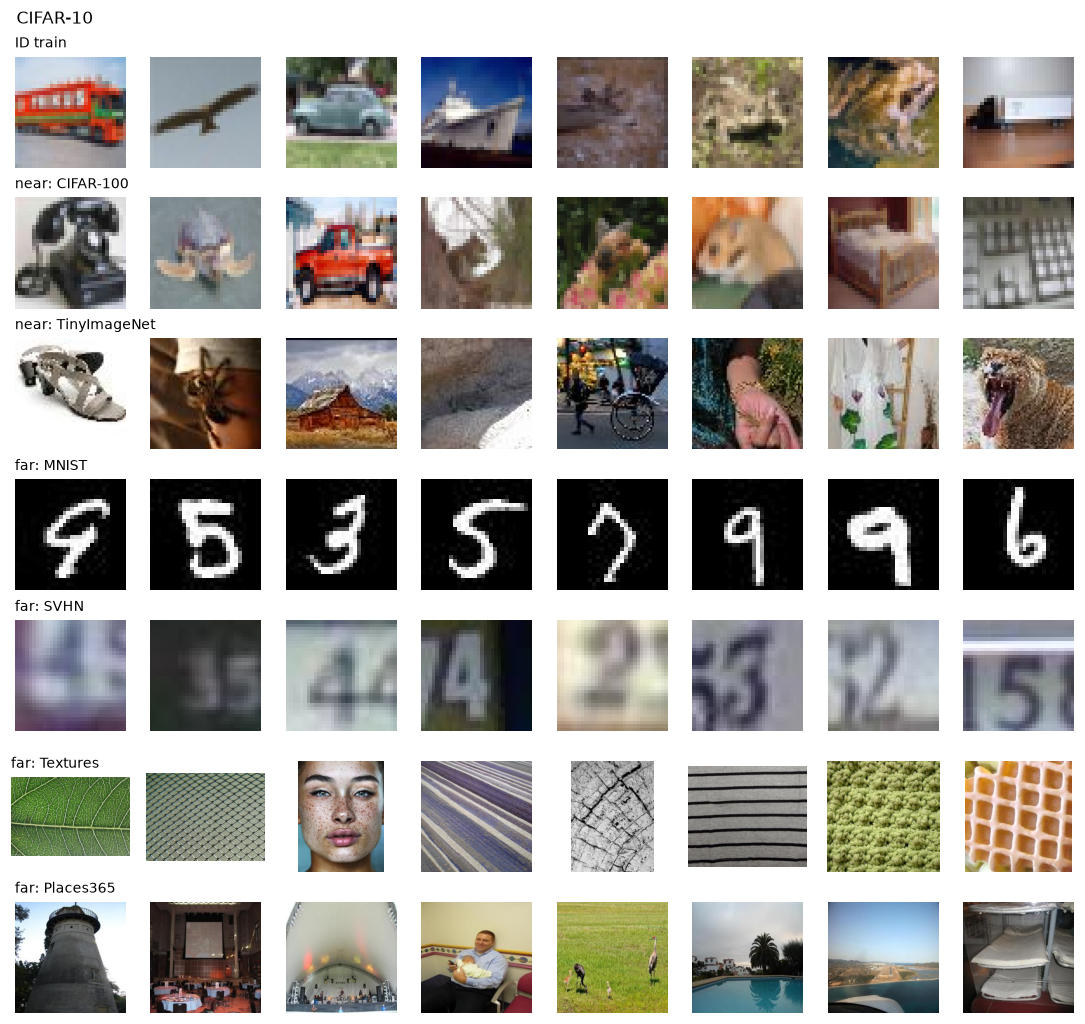

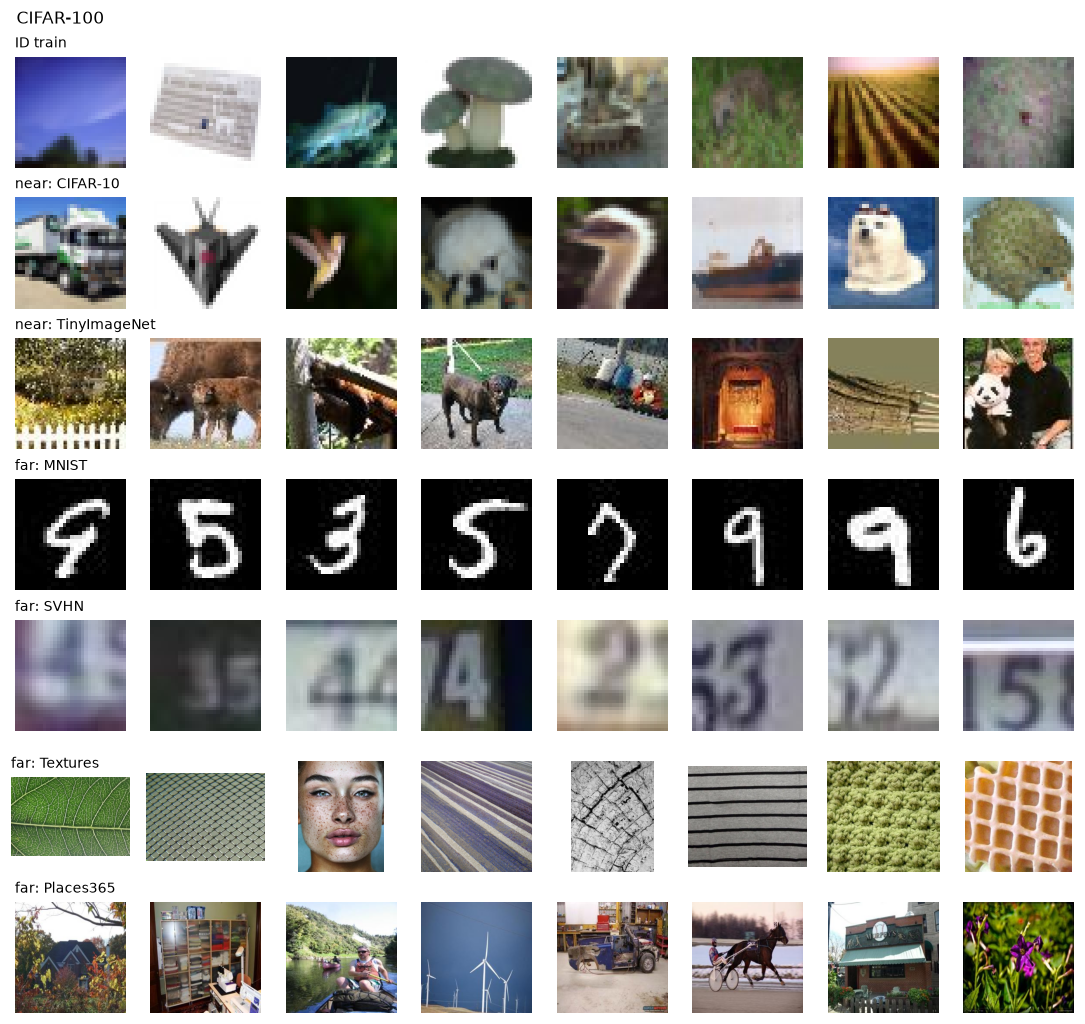

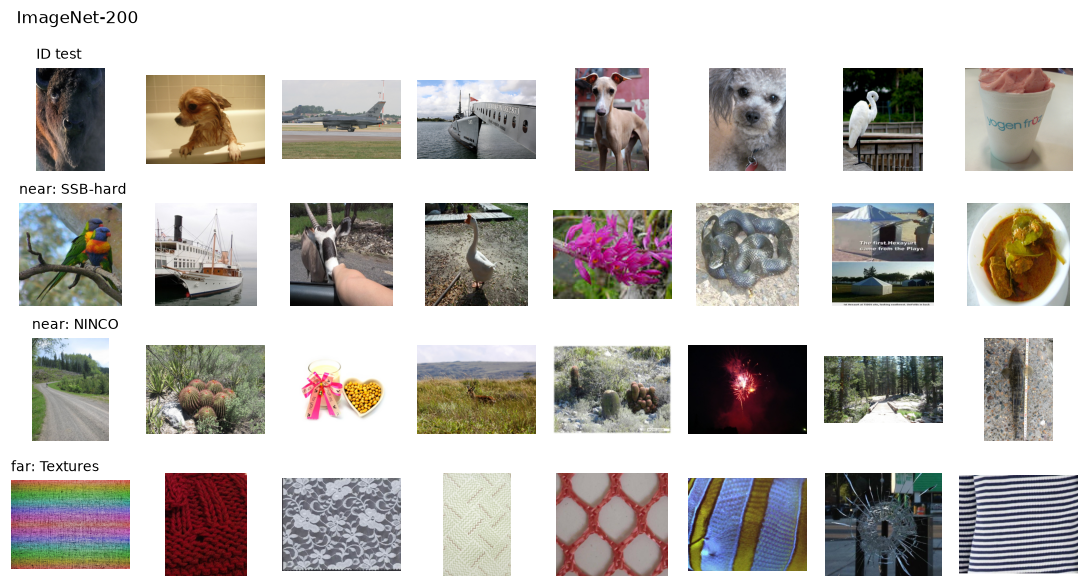

In [4]:
def show_row(ax_row, df, title, n):
    pick = df.sample(n, random_state=0)
    for ax, p in zip(ax_row, pick.path):
        f = resolve(p)
        if f is not None:
            ax.imshow(Image.open(f).convert('RGB'))
        ax.axis('off')
    ax_row[0].set_title(title, fontsize=9, loc='left')

for ds in SETS:
    groups = [('ID ' + ('test' if ds == 'ImageNet-200' else 'train'), L[(ds, 'test' if ds == 'ImageNet-200' else 'train')])]
    groups += [(f'{k}: {n}', L[(ds, n)]) for k in ('near', 'far') for n in SETS[ds][k]]
    fig, axes = plt.subplots(len(groups), 8, figsize=(10, 1.35 * len(groups)))
    for row, (t, df) in zip(axes, groups):
        show_row(row, df, t, 8)
    fig.suptitle(ds, fontsize=11, x=0.02, ha='left'); plt.tight_layout(); plt.show()

**Nhận xét**
- Near-OOD giống ID về nội dung: CIFAR-100 và CIFAR-10 cùng là vật thể tự nhiên 32×32; SSB-hard, NINCO là các lớp ImageNet khác.
- Far-OOD khác hẳn: chữ số MNIST, số nhà SVHN, vân bề mặt Textures, cảnh Places365.

## 4. Kích thước, định dạng, kênh màu

Tối đa 300 ảnh mỗi tập.

In [5]:
def meta(df, n=300):
    out = []
    for p in df.sample(min(n, len(df)), random_state=0).path:
        f = resolve(p)
        if f is None:
            continue
        im = Image.open(f); out.append((im.size[0], im.size[1], im.mode, f.suffix.lower()))
    return pd.DataFrame(out, columns=['w', 'h', 'mode', 'fmt'])

mrows = []
for (ds, name), df in L.items():
    if name in ('train', 'val'):
        continue
    m = meta(df)
    mrows.append([ds, name, len(m), f"{m.w.min()}-{m.w.max()}", f"{m.h.min()}-{m.h.max()}",
                  ', '.join(f'{k}:{v}' for k, v in Counter(m['mode']).items()), ', '.join(sorted(set(m.fmt)))])
meta_tab = pd.DataFrame(mrows, columns=['Bộ ID', 'Tập', 'Mẫu kiểm', 'Rộng (px)', 'Cao (px)', 'Kênh màu', 'Định dạng'])
meta_tab

,Bộ ID,Tập,Mẫu kiểm,Rộng (px),Cao (px),Kênh màu,Định dạng
0,CIFAR-10,test,300,32-32,32-32,RGB:300,.png
1,CIFAR-10,CIFAR-100,300,32-32,32-32,RGB:300,.png
2,CIFAR-10,TinyImageNet,300,64-64,64-64,"RGB:296, L:4",.jpeg
3,CIFAR-10,MNIST,300,28-28,28-28,L:300,.jpg
4,CIFAR-10,SVHN,300,32-32,32-32,RGB:300,.jpg
5,CIFAR-10,Textures,300,300-640,300-640,RGB:300,.jpg
6,CIFAR-10,Places365,300,256-256,256-256,"RGB:299, L:1",.jpg
7,CIFAR-100,test,300,32-32,32-32,RGB:300,.png
8,CIFAR-100,CIFAR-10,300,32-32,32-32,RGB:300,.png
9,CIFAR-100,TinyImageNet,300,64-64,64-64,"RGB:295, L:5",.jpeg


**Nhận xét**
- Kích thước gốc: CIFAR và SVHN 32×32, MNIST 28×28 (ảnh xám), TinyImageNet 64×64, Places365 256×256, Textures 300-640 px, ImageNet-200 và NINCO từ khoảng 100 đến hơn 2.000 px, SSB-hard tối đa 224 px.
- Mọi ảnh được resize về 32×32 (CIFAR) hoặc 224×224 (ImageNet-200) trước khi vào mạng, nhưng dấu vết resize và khác biệt định dạng (CIFAR là PNG, tập lạ là JPEG) có thể còn lại. Cần lưu ý khi đọc kết quả far-OOD.
- TinyImageNet, Places365, ImageNet-200 lẫn ảnh xám, NINCO có ảnh RGBA; tất cả được đổi sang RGB trước khi trích đặc trưng.

## 5. Thống kê pixel

Mỗi tập lấy 400 ảnh, đưa về 32×32 RGB, tính trung bình từng kênh, độ sáng, độ tương phản và độ bão hòa.

In [6]:
def pixel_stats(df, n=400, size=32):
    arr = []
    for p in df.sample(min(n, len(df)), random_state=0).path:
        f = resolve(p)
        if f is not None:
            arr.append(np.asarray(Image.open(f).convert('RGB').resize((size, size)), np.float32) / 255)
    a = np.stack(arr)
    mx, mn = a.max(-1), a.min(-1)
    return a, {'R mean': a[..., 0].mean(), 'G mean': a[..., 1].mean(), 'B mean': a[..., 2].mean(),
               'độ sáng': a.mean(), 'độ tương phản (std)': a.reshape(len(a), -1).std(1).mean(),
               'độ bão hòa': ((mx - mn) / (mx + 1e-6)).mean()}

PX, prow = {}, []
for ds in ('CIFAR-10', 'ImageNet-200'):
    groups = [('ID test', L[(ds, 'test')])] + [(n, L[(ds, n)]) for k in ('near', 'far') for n in SETS[ds][k]]
    for name, df in groups:
        a, st = pixel_stats(df); PX[(ds, name)] = a; prow.append({'Bộ ID': ds, 'Tập': name, **st})
pix = pd.DataFrame(prow).round(3)
pix

,Bộ ID,Tập,R mean,G mean,B mean,độ sáng,độ tương phản (std),độ bão hòa
0,CIFAR-10,ID test,0.490,0.478,0.446,0.471,0.206,0.278
1,CIFAR-10,CIFAR-100,0.501,0.484,0.440,0.475,0.216,0.303
2,CIFAR-10,TinyImageNet,0.485,0.451,0.396,0.444,0.217,0.334
3,CIFAR-10,MNIST,0.133,0.133,0.133,0.133,0.286,0.000
4,CIFAR-10,SVHN,0.452,0.453,0.468,0.458,0.131,0.202
5,CIFAR-10,Textures,0.526,0.468,0.418,0.471,0.160,0.320
6,CIFAR-10,Places365,0.451,0.436,0.404,0.430,0.222,0.291
7,ImageNet-200,ID test,0.475,0.448,0.395,0.440,0.215,0.320
8,ImageNet-200,SSB-hard,0.482,0.480,0.435,0.466,0.208,0.295
9,ImageNet-200,NINCO,0.498,0.480,0.429,0.469,0.193,0.300


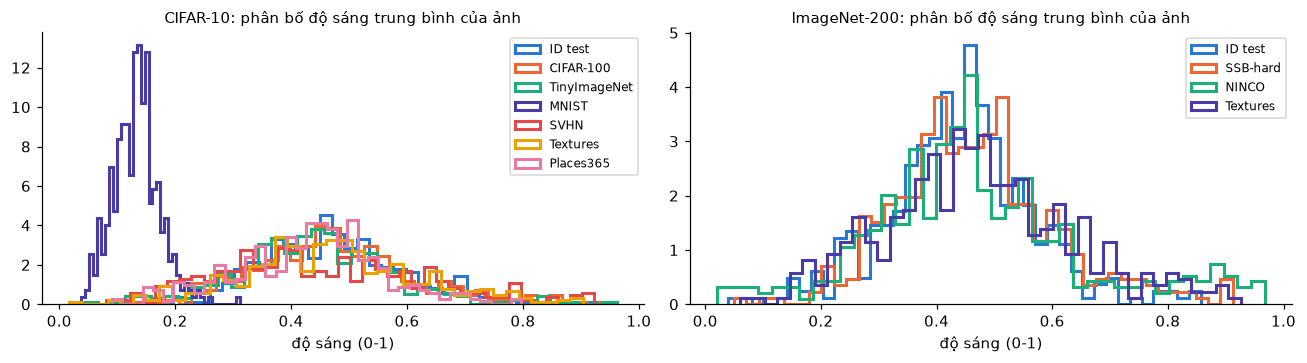

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
for ax, ds in zip(axes, ('CIFAR-10', 'ImageNet-200')):
    names = [n for (d, n) in PX if d == ds]
    for i, n in enumerate(names):
        ax.hist(PX[(ds, n)].mean(axis=(1, 2, 3)), bins=40, histtype='step', lw=2, density=True, color=C[i % len(C)], label=n)
    ax.set_title(f'{ds}: phân bố độ sáng trung bình của ảnh', fontsize=10); ax.set_xlabel('độ sáng (0-1)'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Nhận xét**
- MNIST khác hẳn: tối (độ sáng 0.13 so với 0.47 của CIFAR-10), tương phản cao (0.29 so với 0.21), không có màu.
- SVHN và Textures tương phản thấp (0.13 và 0.16).
- Near-OOD gần như trùng ID: CIFAR-100 có độ sáng 0.475 so với 0.471 của CIFAR-10; SSB-hard, NINCO 0.47 so với 0.44 của ImageNet-200.
- Vì vậy tín hiệu tách near-OOD nằm ở ngữ nghĩa, tức trong đặc trưng của mạng, không ở màu hay độ sáng. Far-OOD như MNIST thì thống kê pixel đã đủ tách.

## 6. Trùng lặp giữa các tập

Ảnh trùng giữa gallery và test, hoặc giữa ID và OOD, sẽ thổi phồng điểm kNN. Kiểm bằng MD5 của pixel trên 2.000 ảnh mỗi tập.

In [8]:
def hashes(df, n=2000):
    out = set()
    for p in df.sample(min(n, len(df)), random_state=0).path:
        f = resolve(p)
        if f is not None:
            out.add(hashlib.md5(np.asarray(Image.open(f).convert('RGB')).tobytes()).hexdigest())
    return out

H = {k: hashes(L[k]) for k in [('CIFAR-10', 'train'), ('CIFAR-10', 'test'), ('CIFAR-10', 'CIFAR-100'), ('CIFAR-10', 'TinyImageNet'),
                               ('CIFAR-100', 'train'), ('CIFAR-100', 'test')]}
pairs = [(('CIFAR-10', 'train'), ('CIFAR-10', 'test')), (('CIFAR-10', 'test'), ('CIFAR-10', 'CIFAR-100')),
         (('CIFAR-10', 'test'), ('CIFAR-10', 'TinyImageNet')), (('CIFAR-100', 'train'), ('CIFAR-100', 'test'))]
pd.DataFrame([[f'{a[0]} {a[1]}', f'{b[0]} {b[1]}', len(H[a]), len(H[b]), len(H[a] & H[b])] for a, b in pairs],
             columns=['Tập 1', 'Tập 2', 'Mẫu 1', 'Mẫu 2', 'Trùng hệt'])

,Tập 1,Tập 2,Mẫu 1,Mẫu 2,Trùng hệt
0,CIFAR-10 train,CIFAR-10 test,2000,2000,0
1,CIFAR-10 test,CIFAR-10 CIFAR-100,2000,2000,0
2,CIFAR-10 test,CIFAR-10 TinyImageNet,2000,2000,0
3,CIFAR-100 train,CIFAR-100 test,2000,2000,0


**Nhận xét.** Không có ảnh trùng hệt giữa train và test, hay giữa ID và near-OOD. Phép kiểm này không bắt được ảnh gần giống.

# Phần B. Đặc trưng

Thử nghiệm làm việc trên đặc trưng ResNet18 đóng băng (checkpoint chính thức OpenOOD v1.5), chuẩn hóa L2. Điểm tĩnh $s_0$ là cosine tới láng giềng thứ K trong gallery; ở đây dùng K = 10 cho mọi bộ.

In [9]:
try:
    import torch
    DEV = 'cuda' if torch.cuda.is_available() else 'cpu'
except ImportError:
    torch, DEV = None, 'cpu'
K = 10

def l2(a):
    a = np.asarray(a, np.float32); return a / (np.linalg.norm(a, axis=1, keepdims=True) + 1e-12)

def kth_sim(x, g, k, block=4096):
    out = []
    if torch is not None:
        gt = torch.as_tensor(g, device=DEV)
        for i in range(0, len(x), block):
            out.append((torch.as_tensor(x[i:i + block], device=DEV) @ gt.T).topk(k, dim=1).values[:, -1].cpu().numpy())
    else:
        for i in range(0, len(x), block):
            out.append(np.partition(x[i:i + block] @ g.T, -k, axis=1)[:, -k])
    return np.concatenate(out)

def auroc(s_id, s_ood):
    return 100 * roc_auc_score(np.r_[np.zeros(len(s_id)), np.ones(len(s_ood))], -np.r_[s_id, s_ood])

data = {}
for ds, fn, near, far in [('CIFAR-10', 'resnet18_official_v15.npz', ['cifar100', 'tin'], ['mnist', 'svhn', 'texture', 'places365']),
                          ('CIFAR-100', 'resnet18_cifar100_v15.npz', ['cifar10', 'tin'], ['mnist', 'svhn', 'texture', 'places365'])]:
    d = np.load(FEAT / fn)
    data[ds] = dict(G=l2(d['id_train_feats']), T=l2(d['id_test_feats']), near=near, ood={o: l2(d[f'{o}_feats']) for o in near + far})
d = np.load(FEAT / 'resnet18_in200_v15.npz'); lab = d['id_labels']; rng = np.random.default_rng(0); A, B = [], []
for c in np.unique(lab):  # cùng cách chia với thử nghiệm
    i = rng.permutation(np.flatnonzero(lab == c)); A += list(i[:len(i) // 2]); B += list(i[len(i) // 2:])
A = rng.permutation(A)
data['ImageNet-200'] = dict(G=l2(d['id_feats'][A[:int(.8 * len(A))]]), T=l2(d['id_feats'][B]), near=['ssb_hard', 'ninco'],
                            ood={o: l2(d[f'{o}_feats']) for o in ['ssb_hard', 'ninco', 'textures']})
for v in data.values():
    v['s_id'] = kth_sim(v['T'], v['G'], K); v['s_ood'] = {o: kth_sim(x, v['G'], K) for o, x in v['ood'].items()}
print({ds: v['G'].shape for ds, v in data.items()})

{'CIFAR-10': (50000, 512), 'CIFAR-100': (50000, 512), 'ImageNet-200': (3520, 512)}


## 7. Độ khó với kNN tĩnh

,Bộ ID,Tập lạ,Loại,AUROC kNN
0,CIFAR-10,cifar100,near,90.1
1,CIFAR-10,tin,near,92.0
2,CIFAR-10,mnist,far,94.0
3,CIFAR-10,svhn,far,92.5
4,CIFAR-10,texture,far,93.7
5,CIFAR-10,places365,far,91.8
6,CIFAR-100,cifar10,near,77.2
7,CIFAR-100,tin,near,83.4
8,CIFAR-100,mnist,far,83.5
9,CIFAR-100,svhn,far,82.8


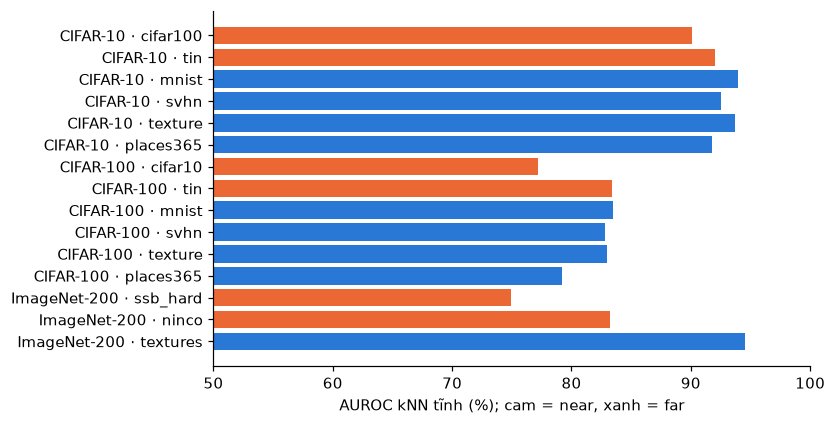

In [10]:
diff = pd.DataFrame([[ds, o, 'near' if o in v['near'] else 'far', auroc(v['s_id'], s)] for ds, v in data.items() for o, s in v['s_ood'].items()],
                    columns=['Bộ ID', 'Tập lạ', 'Loại', 'AUROC kNN'])
display(diff.round(1))
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.barh(diff['Bộ ID'] + ' · ' + diff['Tập lạ'], diff['AUROC kNN'], color=[C[1] if k == 'near' else C[0] for k in diff['Loại']])
ax.invert_yaxis(); ax.set_xlim(50, 100); ax.set_xlabel('AUROC kNN tĩnh (%); cam = near, xanh = far'); plt.show()

**Nhận xét**
- CIFAR-10 gần trần (90-94), CIFAR-100 khó ở cả near lẫn far (77-84), ImageNet-200 SSB-hard khó nhất (74.9).
- Đây là những chỗ bộ nhớ động còn dư địa.

## 8. Phân bố điểm và t-SNE

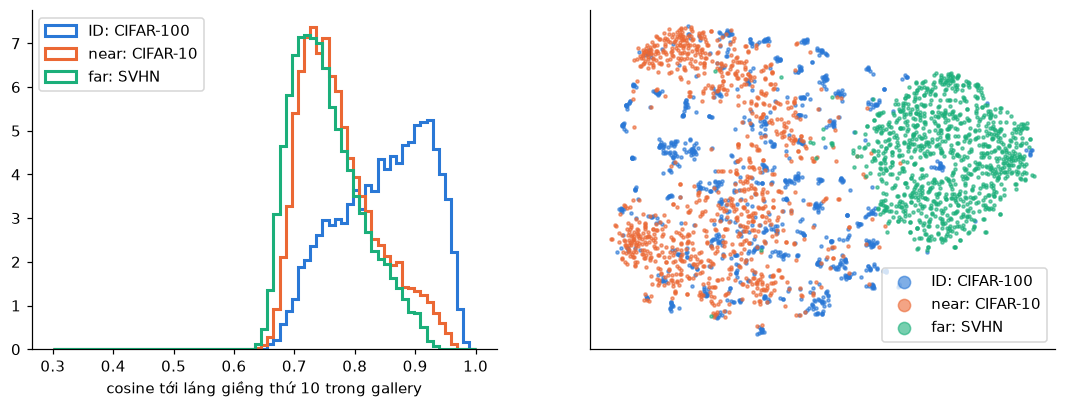

In [11]:
v = data['CIFAR-100']; bins = np.linspace(.3, 1, 70)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for s, name, c in [(v['s_id'], 'ID: CIFAR-100', C[0]), (v['s_ood']['cifar10'], 'near: CIFAR-10', C[1]), (v['s_ood']['svhn'], 'far: SVHN', C[2])]:
    axes[0].hist(s, bins=bins, density=True, histtype='step', lw=2, color=c, label=name)
axes[0].set_xlabel('cosine tới láng giềng thứ 10 trong gallery'); axes[0].legend()
parts = [(v['T'], 'ID: CIFAR-100', C[0]), (v['ood']['cifar10'], 'near: CIFAR-10', C[1]), (v['ood']['svhn'], 'far: SVHN', C[2])]
X = np.concatenate([p[0][RNG.choice(len(p[0]), 1000, replace=False)] for p in parts])
E = TSNE(n_components=2, init='pca', random_state=0, perplexity=30).fit_transform(X)
for i, (_, name, c) in enumerate(parts):
    axes[1].scatter(*E[i * 1000:(i + 1) * 1000].T, s=4, color=c, alpha=.6, label=name)
axes[1].set_xticks([]); axes[1].set_yticks([]); axes[1].legend(markerscale=4); plt.show()

**Nhận xét**
- Phân bố điểm của CIFAR-10 (near) và SVHN (far) gần trùng nhau: điểm tĩnh không phân biệt được hai loại.
- Trên t-SNE, SVHN thành cụm riêng; CIFAR-10 xen với CIFAR-100 nhưng vẫn có vùng dày riêng. Bộ nhớ động khai thác việc các mẫu lạ giống nhau, điều điểm tĩnh không thấy.

## 9. Dữ liệu lạ có tụ cụm không

Lấy 500 mẫu lạ và 500 mẫu quen, đo tỉ lệ mẫu lạ có láng giềng gần nhất cũng là mẫu lạ. Không tụ cụm thì tỉ lệ khoảng 50%.

,Bộ ID,Tập lạ,Loại,Tỉ lệ cùng loại (%)
0,CIFAR-10,cifar100,near,68.8
1,CIFAR-10,tin,near,74.8
2,CIFAR-10,mnist,far,97.0
3,CIFAR-10,svhn,far,97.2
4,CIFAR-10,texture,far,85.6
5,CIFAR-10,places365,far,82.4
6,CIFAR-100,cifar10,near,76.2
7,CIFAR-100,tin,near,67.8
8,CIFAR-100,mnist,far,100.0
9,CIFAR-100,svhn,far,99.8


,count,mean,std,min,25%,50%,75%,max
Loại,,,,,,,,
far,9.0,89.3,9.5,73.6,82.4,86.8,97.2,100.0
near,6.0,74.6,6.3,67.8,70.2,74.6,75.8,85.4


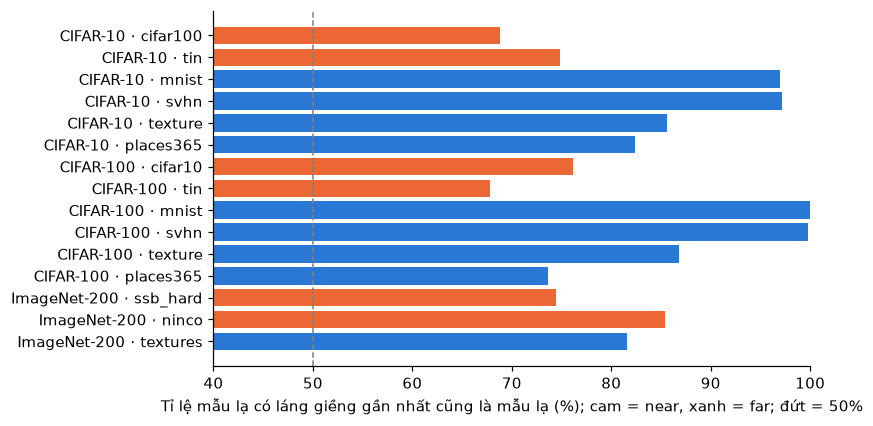

In [12]:
def same_nn_rate(a, b, n=500):
    r = np.random.default_rng(0)
    a = a[r.choice(len(a), min(n, len(a)), replace=False)]; b = b[r.choice(len(b), min(n, len(b)), replace=False)]
    s = a @ np.r_[a, b].T; s[np.arange(len(a)), np.arange(len(a))] = -9
    return 100 * np.mean(s.argmax(1) < len(a))

clu = pd.DataFrame([[ds, o, 'near' if o in v['near'] else 'far', same_nn_rate(x, v['T'])] for ds, v in data.items() for o, x in v['ood'].items()],
                   columns=['Bộ ID', 'Tập lạ', 'Loại', 'Tỉ lệ cùng loại (%)'])
display(clu.round(1))
display(clu.groupby('Loại')['Tỉ lệ cùng loại (%)'].describe().round(1))
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.barh(clu['Bộ ID'] + ' · ' + clu['Tập lạ'], clu['Tỉ lệ cùng loại (%)'], color=[C[1] if k == 'near' else C[0] for k in clu['Loại']])
ax.axvline(50, color='gray', ls='--', lw=1)
ax.invert_yaxis(); ax.set_xlim(40, 100); ax.set_xlabel('Tỉ lệ mẫu lạ có láng giềng gần nhất cũng là mẫu lạ (%); cam = near, xanh = far; đứt = 50%'); plt.show()

**Nhận xét.** Mọi tập lạ đều trên 50%. Far-OOD tụ mạnh (MNIST, SVHN 97-100%), near-OOD yếu hơn (68-85%), nên bộ nhớ có ích nhất ở far-OOD.

## 10. Trôi dạt (CIFAR-10-C)

kNN tĩnh coi ảnh CIFAR-10 bị biến dạng (nhiễu, mờ, sương mù, độ sáng, JPEG; mức 3 và 5) là lạ đến đâu, so với near-OOD thật?

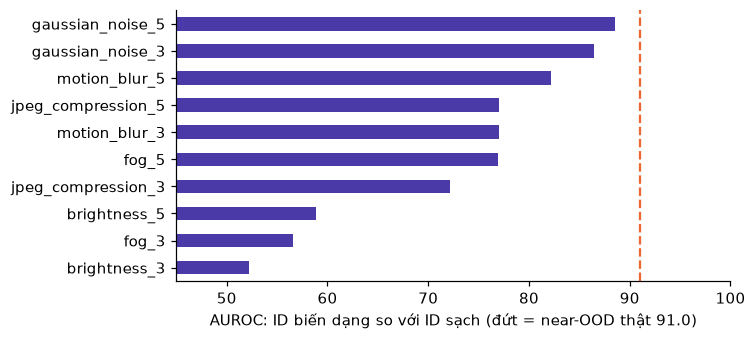

brightness_3          52.2
fog_3                 56.6
brightness_5          58.9
jpeg_compression_3    72.1
fog_5                 76.9
motion_blur_3         77.0
jpeg_compression_5    77.0
motion_blur_5         82.2
gaussian_noise_3      86.5
gaussian_noise_5      88.5
dtype: float64

In [13]:
c = np.load(FEAT / 'cifar10c_official.npz'); v10 = data['CIFAR-10']
drift = pd.Series({k[:-6]: auroc(v10['s_id'], kth_sim(l2(c[k]), v10['G'], K)) for k in c.keys() if k.endswith('_feats')}).sort_values()
near_ref = diff.query("`Bộ ID` == 'CIFAR-10' and Loại == 'near'")['AUROC kNN'].mean()
ax = drift.plot.barh(figsize=(6.5, 3.2), color=C[3]); ax.axvline(near_ref, color=C[1], ls='--')
ax.set_xlim(45, 100); ax.set_xlabel(f'AUROC: ID biến dạng so với ID sạch (đứt = near-OOD thật {near_ref:.1f})'); plt.show()
drift.round(1)

**Nhận xét.** Nhiễu Gauss mức 5 làm ảnh quen trông lạ gần bằng near-OOD thật; độ sáng mức 3 gần như không đổi. Bộ nhớ không nhãn sẽ coi ảnh quen trôi mạnh là lạ, nên CURE cần chứng nhận và lối lùi về điểm tĩnh.

## 11. Tóm tắt

| Phát hiện | Hệ quả cho CURE |
|---|---|
| ID cân bằng lớp, không có ảnh trùng giữa các tập | kNN không thiên lớp, không rò rỉ |
| Near-OOD giống ID cả về nội dung lẫn pixel | near-OOD là phần khó nhất |
| Far-OOD khác ở thống kê pixel và tụ cụm mạnh | bộ nhớ có ích nhất ở far-OOD |
| CIFAR-100, ImageNet-200 SSB-hard còn khó với kNN | bộ nhớ còn dư địa |
| Mọi tập lạ đều tụ cụm | kênh bộ nhớ có cơ sở |
| Trôi dạt mạnh làm ảnh quen trông như lạ | cần chứng nhận và lối lùi |